# Solutions — exercises of `01-lagrangian-bickley-jet.ipynb`

One section per exercise of B10. Units: km and days. Run time about 2 minutes.

In [1]:
import sys
import time
sys.path.insert(0, "..")            # lagkit.py is in the repository root

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

import lagkit as lk

bj = lk.BickleyJet()
velocity, vorticity, Lx = bj.velocity, bj.vorticity, bj.Lx
T0, DT = 20.0, 0.1
rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "image.origin": "lower"})


def ftle_map(nx, ny, T, dt=DT, vel=velocity):
    # forward (T > 0) or backward (T < 0) FTLE at t0 = T0 on an nx x ny grid
    x = np.linspace(0, Lx, nx, endpoint=False)
    y = np.linspace(-3000, 3000, ny)
    X, Y = np.meshgrid(x, y)
    xf, yf = lk.advect(X, Y, T0, T, dt, vel)
    return x, y, lk.ftle_from_flowmap(xf, yf, x[1] - x[0], y[1] - y[0], T, periodic_x=Lx)

## Exercise 1 — Convergence in time step and in grid spacing

halving dt       : pattern correlation 0.9993, mean 0.1983 -> 0.1983, max 0.353 -> 0.353
doubling the grid: pattern correlation 0.8655, mean 0.1983 -> 0.2067, max 0.353 -> 0.382
chaotic band : position error after 20 d  dt=0.1:   983.31 km,  dt=0.05:   54.48 km  (reference dt=0.025)
eddy core    : position error after 20 d  dt=0.1:     0.32 km,  dt=0.05:    0.02 km  (reference dt=0.025)


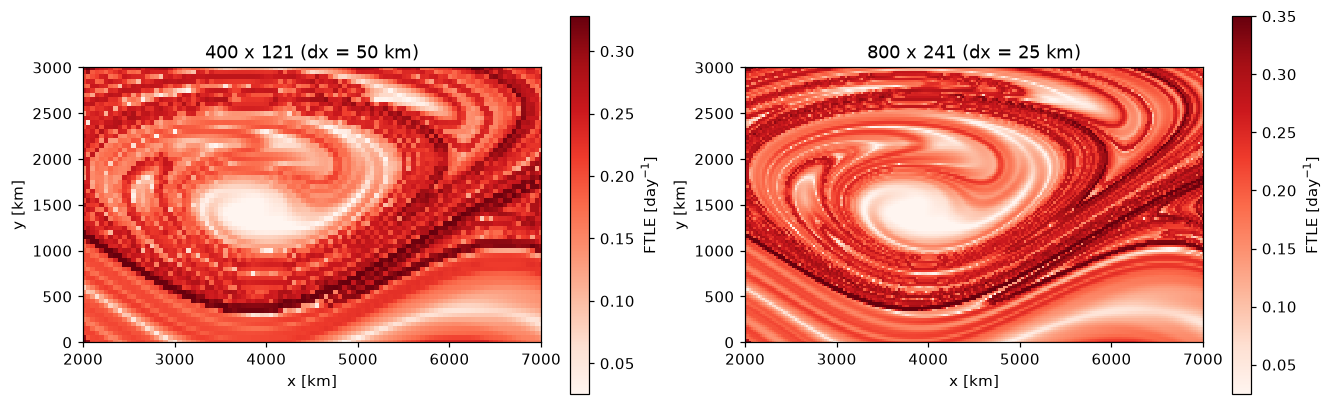

In [2]:
x1, y1, f_ref = ftle_map(400, 121, 20.0, dt=0.1)
_, _, f_dt = ftle_map(400, 121, 20.0, dt=0.05)
x2, y2, f_fine = ftle_map(800, 241, 20.0, dt=0.1)

corr = lambda a, b: np.corrcoef(a.ravel(), b.ravel())[0, 1]
print(f"halving dt       : pattern correlation {corr(f_ref, f_dt):.4f}, mean {f_ref.mean():.4f} -> {f_dt.mean():.4f}, max {f_ref.max():.3f} -> {f_dt.max():.3f}")
print(f"doubling the grid: pattern correlation {corr(f_ref, f_fine[::2, ::2]):.4f}, mean {f_ref.mean():.4f} -> {f_fine.mean():.4f}, max {f_ref.max():.3f} -> {f_fine.max():.3f}")

for name, (xa, ya) in {"chaotic band": (2500.0, 1300.0), "eddy core": (4000.0, 880.0)}.items():
    end = [np.array(lk.advect(xa, ya, 0.0, 20.0, dt, velocity)) for dt in (0.1, 0.05, 0.025)]
    print(f"{name:13s}: position error after 20 d  dt=0.1: {np.hypot(*(end[0] - end[2])):8.2f} km,  dt=0.05: {np.hypot(*(end[1] - end[2])):7.2f} km  (reference dt=0.025)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
win = dict(xlim=(2000, 7000), ylim=(0, 3000))
lk.plot_field(axes[0], x1, y1, f_ref, kind="ftle_fwd", label="FTLE [day$^{-1}$]", title="400 x 121 (dx = 50 km)")
lk.plot_field(axes[1], x2, y2, f_fine, kind="ftle_fwd", label="FTLE [day$^{-1}$]", title="800 x 241 (dx = 25 km)")
for ax in axes:
    ax.set(xlabel="x [km]", ylabel="y [km]", aspect="equal", **win)
plt.show()

**Answer.** Halving the time step leaves the map unchanged (pattern correlation 0.999, same mean and maximum): `DT = 0.1` day is already converged *for the map*. Doubling the grid resolution changes it much more (correlation about 0.87 on the common points, larger maximum): the ridges are thinner than the grid, so a finer grid resolves more of them and samples their crests better. FTLE maps are limited by the spatial sampling of the flow map (A9), not by the integrator.

Single trajectories behave differently. In the eddy core the end point is converged to better than 1 km. In the chaotic band the end point moves by about 1000 km when the step is halved once and by about 50 km when halved again: errors grow like $e^{\sigma t}$ there. Individual chaotic trajectories are not predictable over 20 days; the statistics and the maps are.

## Exercise 2 — A single wave: chaos switched off

three waves       : y range of the blob after 20 d:   -785 to   3892 km
one wave (steady) : y range of the blob after 20 d:    696 to   1902 km


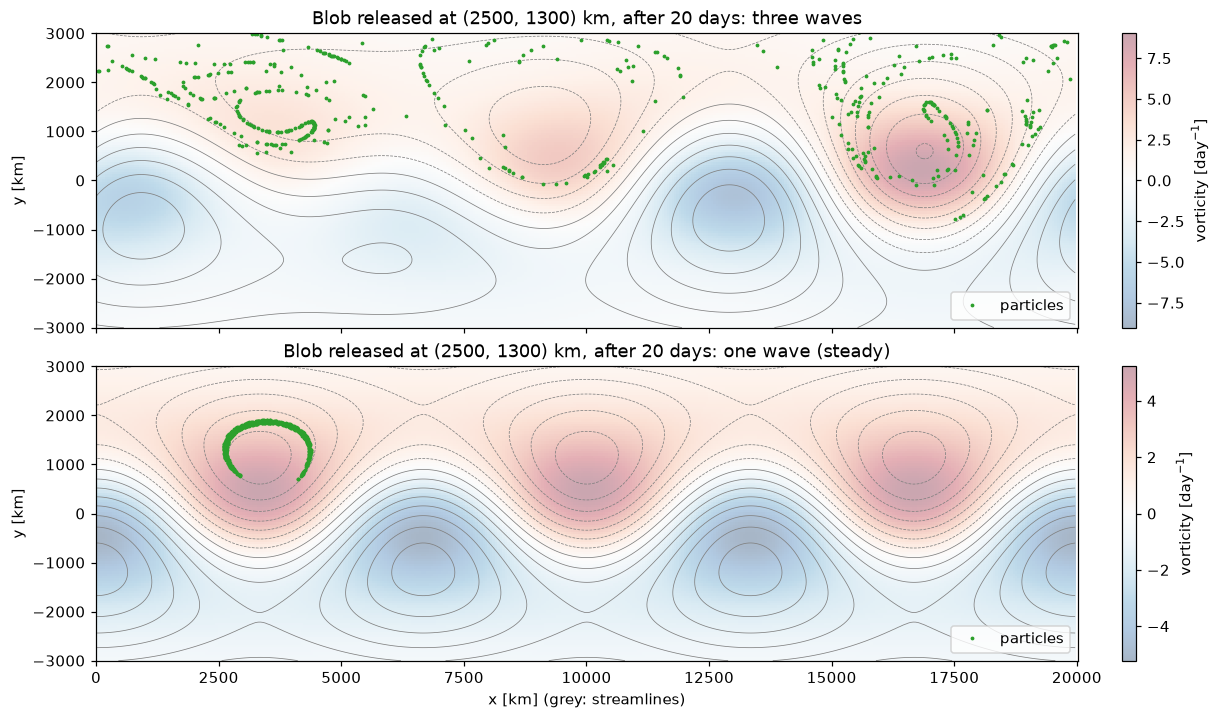

one wave, T = 20 d: mean FTLE 0.161, max 0.322 1/day


one wave, T = 40 d: mean FTLE 0.092, max 0.177 1/day


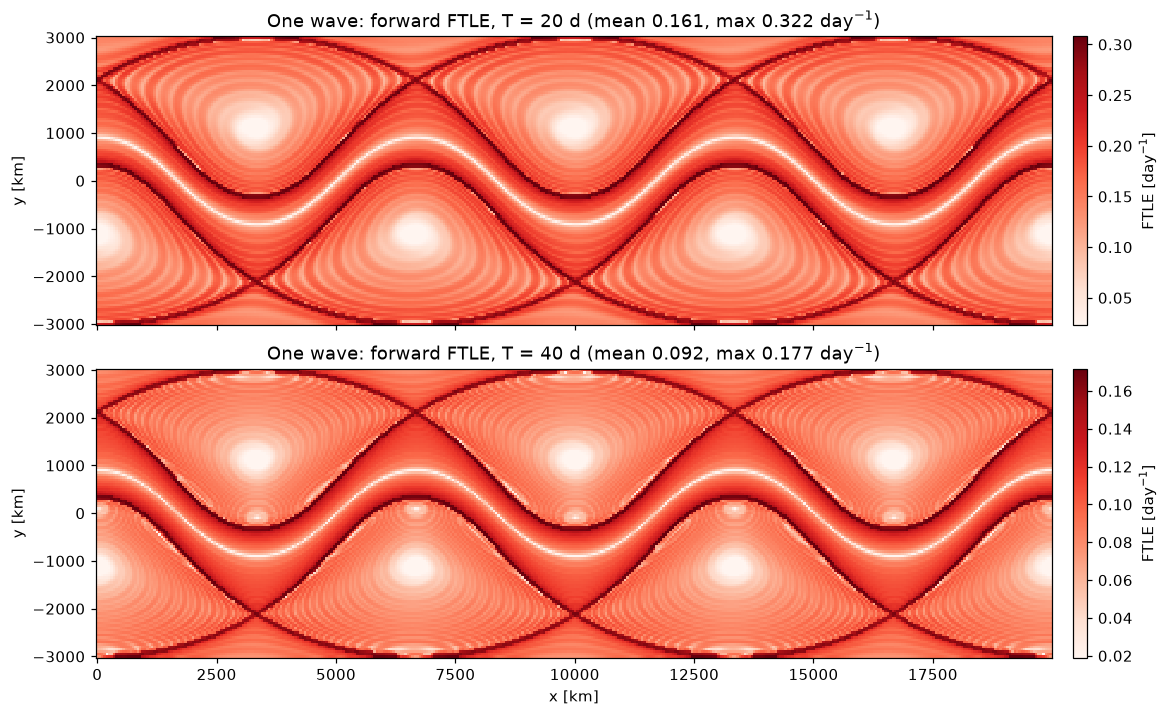

In [3]:
bj1 = lk.BickleyJet(eps=(0, 0, 0.3))              # steady in the frame moving with c3
xg = np.linspace(0, Lx, 400, endpoint=False)
yg = np.linspace(-3000, 3000, 121)
XG, YG = np.meshgrid(xg, yg)

r = 250 * np.sqrt(rng.uniform(0, 1, 600))
th = rng.uniform(0, 2 * np.pi, 600)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True)
for ax, (flow, label) in zip(axes, ((bj, "three waves"), (bj1, "one wave (steady)"))):
    lk.plot_field(ax, xg, yg, flow.vorticity(XG, YG, 20.0), kind="vorticity", robust=False, alpha=0.35,
                  label="vorticity [day$^{-1}$]", title=f"Blob released at (2500, 1300) km, after 20 days: {label}")
    ax.contour(xg, yg, flow.psi(XG, YG, 20.0), levels=15, colors="0.5", linewidths=0.5)
    xf, yf = lk.advect(2500 + r * np.cos(th), 1300 + r * np.sin(th), 0.0, 20.0, 0.05, flow.velocity)
    ax.plot(np.mod(xf, Lx), yf, ".", ms=3, color="tab:green", label="particles")
    ax.set(ylabel="y [km]", aspect="equal", xlim=(0, Lx), ylim=(-3000, 3000))
    ax.legend(loc="lower right")
    print(f"{label:18s}: y range of the blob after 20 d: {yf.min():6.0f} to {yf.max():6.0f} km")
axes[-1].set_xlabel("x [km] (grey: streamlines)")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True)
for ax, T in zip(axes, (20.0, 40.0)):
    x, y, f = ftle_map(400, 121, T, vel=bj1.velocity)
    lk.plot_field(ax, x, y, f, kind="ftle_fwd", label="FTLE [day$^{-1}$]",
                  title=f"One wave: forward FTLE, T = {T:.0f} d (mean {f.mean():.3f}, max {f.max():.3f} day$^{{-1}}$)")
    ax.set(ylabel="y [km]", aspect="equal")
    print(f"one wave, T = {T:.0f} d: mean FTLE {f.mean():.3f}, max {f.max():.3f} 1/day")
axes[-1].set_xlabel("x [km]")
plt.show()

**Answer.** With one wave the flow is steady in this frame, so particles follow streamlines. The blob released in what was the chaotic band is sheared along its streamlines but stays within a band of latitudes: the chaotic band has disappeared. Chaos needs time dependence (at least two waves with different speeds).

The FTLE is not zero, though. Its mean is about 0.16 day⁻¹ for $T=20$ d, not far from the 0.20 of the chaotic flow. But it halves when $T$ doubles (0.09 for $T=40$ d), and so does its maximum. That is the signature of **shear**: neighbouring streamlines carry particles at different speeds, the separation grows linearly in time, and $\sigma\approx\ln(ST)/T\to0$. In a chaotic region the FTLE tends to a positive constant instead. The ridges of the steady case lie along the separatrices (the streamlines through the saddle points, where the travel time diverges) and the flanks of the jet.

So a high FTLE at one value of $T$ does not prove exponential stretching or chaotic mixing. Check how it depends on $T$, or use a diagnostic that separates shear from strain.

## Exercise 3 — Domain-mean FTLE as a function of T

T =    2 d: mean FTLE = 0.654 1/day
T =    5 d: mean FTLE = 0.409 1/day
T =   10 d: mean FTLE = 0.281 1/day
T =   20 d: mean FTLE = 0.190 1/day
T =   30 d: mean FTLE = 0.145 1/day
T =   40 d: mean FTLE = 0.116 1/day
T -> 0 limit (mean largest strain-rate eigenvalue at t0): 1.133 1/day


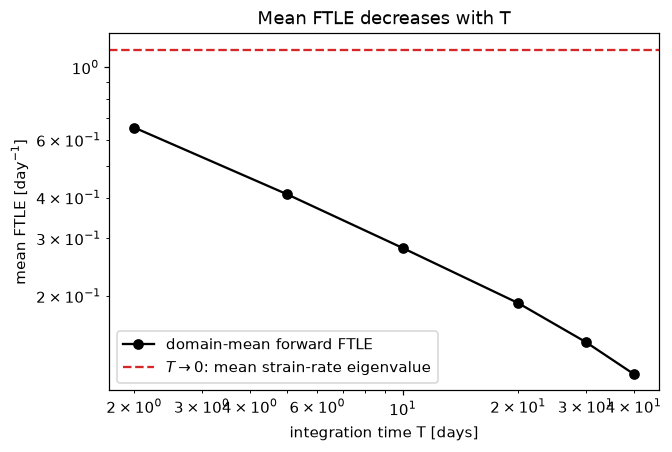

In [4]:
T_list = np.array([2.0, 5.0, 10.0, 20.0, 30.0, 40.0])
means = np.array([ftle_map(240, 73, T)[2].mean() for T in T_list])

U, V = velocity(XG, YG, T0)
W, om, sn, ss = lk.okubo_weiss(U, V, xg[1] - xg[0], yg[1] - yg[0])
strain_eig = 0.5 * np.sqrt(sn ** 2 + ss ** 2)        # largest eigenvalue of the strain-rate tensor
for T, m in zip(T_list, means):
    print(f"T = {T:4.0f} d: mean FTLE = {m:.3f} 1/day")
print(f"T -> 0 limit (mean largest strain-rate eigenvalue at t0): {strain_eig.mean():.3f} 1/day")

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.loglog(T_list, means, "o-", color="k", label="domain-mean forward FTLE")
ax.axhline(strain_eig.mean(), color="tab:red", ls="--", label=r"$T\to0$: mean strain-rate eigenvalue")
ax.set(xlabel="integration time T [days]", ylabel="mean FTLE [day$^{-1}$]", title="Mean FTLE decreases with T")
ax.legend()
plt.show()

**Answer.** The mean FTLE decreases monotonically, from 0.65 day⁻¹ at $T=2$ d to about 0.12 at $T=40$ d.

For $T\to0$ the FTLE tends to the largest eigenvalue of the strain-rate tensor, $\tfrac12\sqrt{s_n^2+s_s^2}$ for a non-divergent flow, whose domain mean is 1.13 day⁻¹ here. That instantaneous rate is not sustained: a fluid element does not stay aligned with the stretching direction, because the direction rotates as the element moves through the flow. In the regular regions (eddy cores, jet core, which cover a large part of the domain) the separation grows only algebraically, so their FTLE decays like $\ln T/T$. Only the chaotic regions keep a positive rate. The mean over the domain therefore keeps falling, towards the area-weighted Lyapunov exponent of the chaotic regions.

## Exercise 4 — Is the jet a barrier?

released on y =  +300 km:  690 of 2000 are south of y = -500 km after 40 days


released on y = +1300 km:   56 of 2000 are south of y = -500 km after 40 days



released on y =  +300 km: north side 1236, south side 764;  changed side between days 0-15 and 45-60: 13
      those 13: mean |vorticity| <= 0.11 1/day, mean zonal speed 3039 to 3081 km/day (jet axis)


released on y = +1300 km: north side 1840, south side 160;  changed side between days 0-15 and 45-60: 1
      those 1: mean |vorticity| <= 0.02 1/day, mean zonal speed 3031 to 3031 km/day (jet axis)


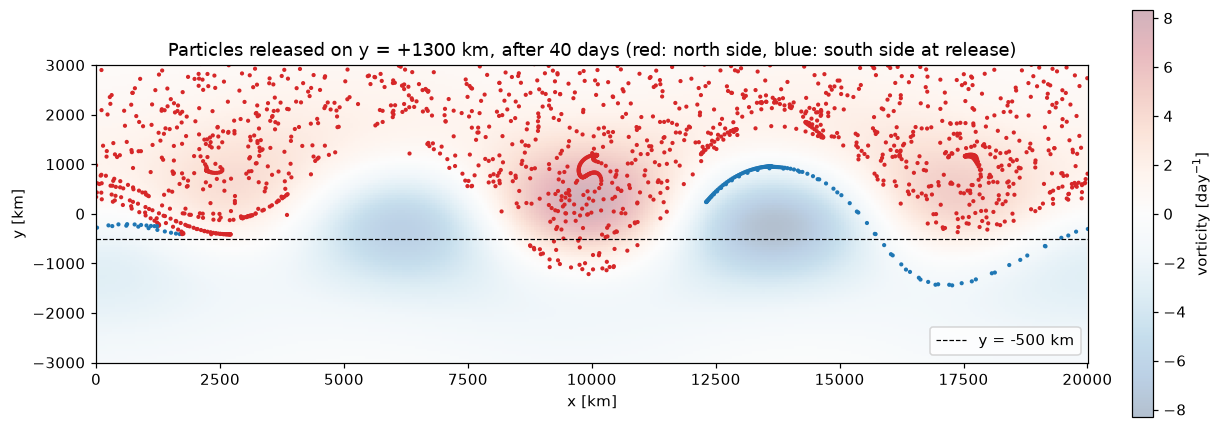

In [5]:
xs = np.linspace(0, Lx, 2000, endpoint=False)
T_RUN = 60.0
tracks = {}
for y0 in (300.0, 1300.0):
    X, Y, t = lk.advect(xs, np.full_like(xs, y0), 0.0, T_RUN, 0.05, velocity, save_every=2)
    tracks[y0] = (X, Y, t)
    i40 = int(np.argmin(np.abs(t - 40.0)))
    print(f"released on y = {y0:+5.0f} km: {int((Y[i40] < -500).sum()):4d} of {len(xs)} are south of y = -500 km after 40 days")

# A better criterion: the sign of the vorticity averaged along the trajectory.
# Cyclones (omega > 0) lie north of the jet and anticyclones (omega < 0) south of it.
print()
for y0, (X, Y, t) in tracks.items():
    om_traj = vorticity(X, Y, t[:, None])
    early, late = om_traj[t <= 15].mean(axis=0), om_traj[t >= T_RUN - 15].mean(axis=0)
    u_mean = velocity(X, Y, t[:, None])[0].mean(axis=0)
    flip = np.sign(early) != np.sign(late)
    print(f"released on y = {y0:+5.0f} km: north side {int((early > 0).sum())}, south side {int((early < 0).sum())};"
          f"  changed side between days 0-15 and 45-60: {int(flip.sum())}")
    if flip.any():
        print(f"      those {int(flip.sum())}: mean |vorticity| <= {max(np.abs(early[flip]).max(), np.abs(late[flip]).max()):.2f} 1/day,"
              f" mean zonal speed {u_mean[flip].min():.0f} to {u_mean[flip].max():.0f} km/day (jet axis)")

X, Y, t = tracks[1300.0]
i40 = int(np.argmin(np.abs(t - 40.0)))
side = np.where(vorticity(X, Y, t[:, None])[t <= 15].mean(axis=0) > 0, "tab:red", "tab:blue")
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
lk.plot_field(ax, xg, yg, vorticity(XG, YG, 40.0), kind="vorticity", robust=False, alpha=0.3, label="vorticity [day$^{-1}$]",
              title="Particles released on y = +1300 km, after 40 days (red: north side, blue: south side at release)")
ax.scatter(np.mod(X[i40], Lx), Y[i40], s=3, c=side)
ax.axhline(-500, color="k", ls="--", lw=0.8, label="y = -500 km")
ax.set(xlabel="x [km]", ylabel="y [km]", aspect="equal", xlim=(0, Lx), ylim=(-3000, 3000))
ax.legend(loc="lower right")
plt.show()

**Answer.** Counting particles south of $y=-500$ km gives 690 (released on $y=+300$) and 56 (released on $y=+1300$), which looks like a leaky jet. It is not. The jet meanders by more than ±2000 km (see the FTLE map of B6), so a fixed latitude does not separate its two sides: a particle at $y=-500$ km can be north of the jet where the jet dips south. Also, neither release line is entirely on one side: both cross the meandering jet at $t=0$. Of the particles released on $y=+1300$ km, 160 have a negative mean vorticity from the start: they are the blue filament in the figure, which lies along the southern half of the jet core.

A criterion that follows the flow: the mean vorticity along the trajectory is positive on the northern (cyclonic) side and negative on the southern side. Comparing the first and the last 15 days of a 60-day run, **no particle changes side**, apart from a handful (1 and 13) that ride on the jet axis itself, where the mean vorticity is essentially zero and its sign has no meaning. Their mean zonal speed, about 3000 km/day, identifies them as jet-core particles.

So the jet core is a transport barrier, consistent with the two FTLE ridges that bound it and with the saturation of $A_y^2$ in B3. The general lesson: decide "which side" with a Lagrangian or material criterion, not with a fixed line on the map.

## Exercise 5 — LAVD: integration time and convexity threshold

T =  10 d, cd_max = 0.005: 6 eddies, R_eq = 501 571 1111 913 655 559 km


T =  10 d, cd_max = 0.020: 6 eddies, R_eq = 585 632 1371 957 719 628 km


T =  10 d, cd_max = 0.100: 6 eddies, R_eq = 1227 1359 1477 1077 891 833 km


T =  30 d, cd_max = 0.005: 6 eddies, R_eq = 296 323 286 310 293 315 km


T =  30 d, cd_max = 0.020: 6 eddies, R_eq = 330 359 309 331 317 354 km


T =  30 d, cd_max = 0.100: 7 eddies, R_eq = 370 407 383 453 543 178 669 km


T =  60 d, cd_max = 0.005: 4 eddies, R_eq = 217 197 231 160 km


T =  60 d, cd_max = 0.020: 6 eddies, R_eq = 271 229 200 169 259 217 km


T =  60 d, cd_max = 0.100: 6 eddies, R_eq = 316 407 271 261 278 264 km


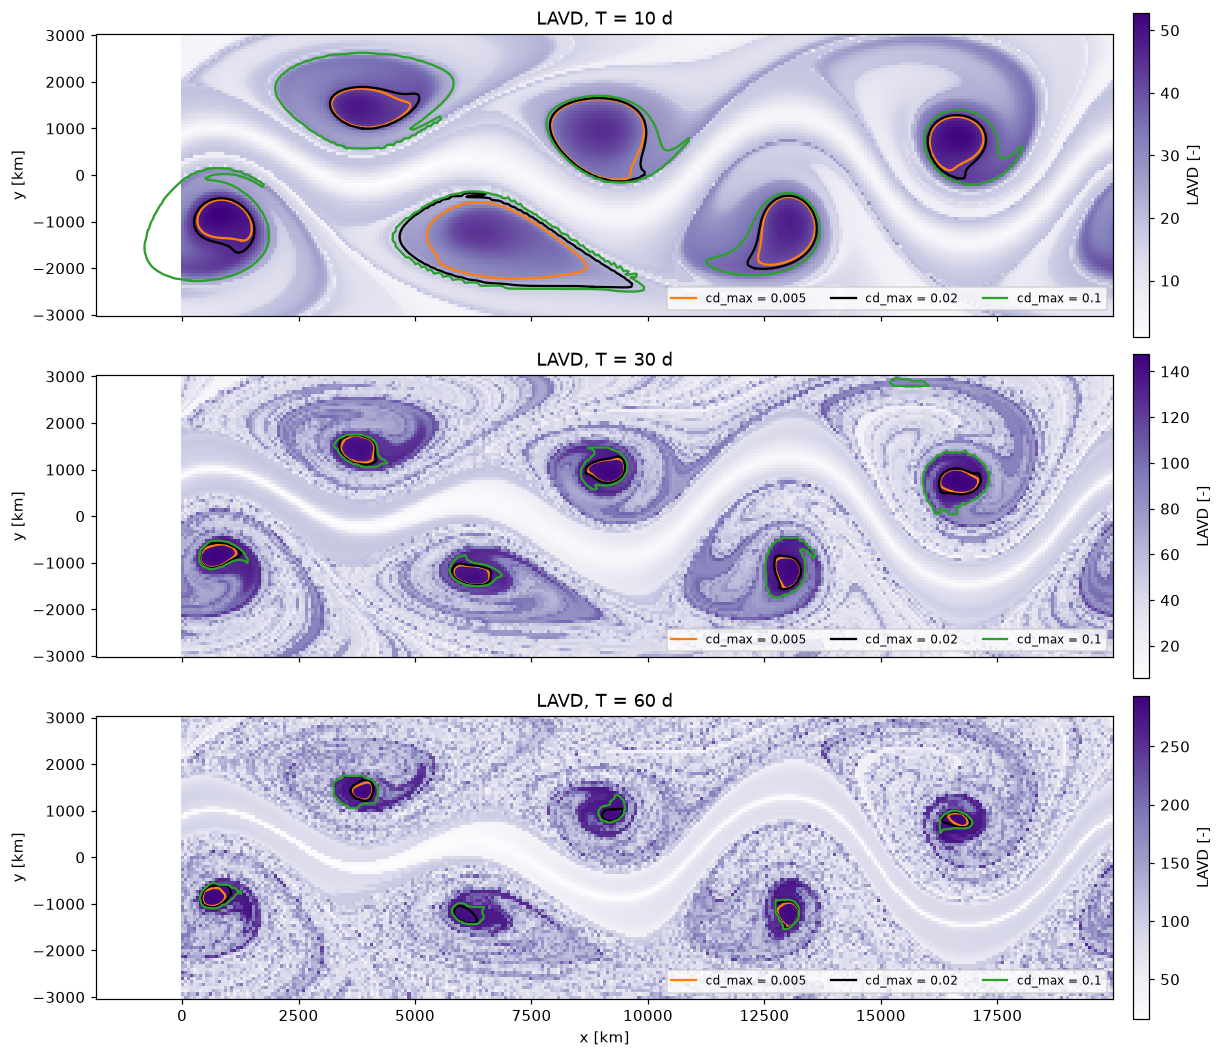

In [6]:
xl = np.linspace(0, Lx, 300, endpoint=False)
yl = np.linspace(-3000, 3000, 91)
XL, YL = np.meshgrid(xl, yl)
fig, axes = plt.subplots(3, 1, figsize=(11, 9.6), sharex=True, constrained_layout=True)
colors = {0.005: "tab:orange", 0.02: "k", 0.1: "tab:green"}
for ax, T in zip(axes, (10.0, 30.0, 60.0)):
    L = lk.lavd(XL, YL, T0, T, DT, velocity, vorticity, 0.0)
    lk.plot_field(ax, xl, yl, L, kind="lavd", label="LAVD [-]", robust=False, title=f"LAVD, T = {T:.0f} d")
    for cd_max, col in colors.items():
        ed = lk.extract_eddies(xl, yl, L, peak_quantile=0.9, box=800, n_levels=150, cd_max=cd_max,
                               min_area=np.pi * 150 ** 2, periodic_x=Lx)
        lk.plot_eddies(ax, ed, color=col, centers=False, label=f"cd_max = {cd_max}")
        print(f"T = {T:3.0f} d, cd_max = {cd_max:5.3f}: {len(ed)} eddies, R_eq = " + " ".join(f"{e['r_eq']:.0f}" for e in ed) + " km")
    ax.set(ylabel="y [km]", aspect="equal")
    ax.legend(loc="lower right", ncol=3, fontsize=8)
axes[-1].set_xlabel("x [km]")
plt.show()

**Answer.**

- **Integration time.** The eddies shrink as $T$ grows: equivalent radii of roughly 500–1400 km for $T=10$ d, 300–350 km for $T=30$ d and 160–270 km for $T=60$ d (with `cd_max` = 0.005–0.02). Coherence is defined over a time interval; the longer you require the water to stay together, the smaller the set that qualifies. With the strictest threshold only four eddies survive at $T=60$ d.
- **Convexity threshold.** A larger `cd_max` accepts less convex contours, so the boundaries grow. With 0.1 they start to include the tails that wrap around the cores, and spurious extra "eddies" can appear (seven at $T=30$ d).
- **Test.** Advect the boundaries over $T$ as in B8 and measure how much their perimeter grows. A boundary that has filamented was not coherent, whatever the threshold that produced it.

There is no universal choice: $T$ should match the time scale of the application, and `cd_max` should be the largest value whose boundaries still pass the advection test.

## Exercise 6 — 5% noise: FTLE versus Okubo–Weiss

rms speed 2434 km/day, noise standard deviation 122 km/day per component


clean: particles that left the grid 0, mean backward FTLE 0.281 1/day, sigma_W 14.4, Okubo-Weiss regions below threshold: 7


noisy: particles that left the grid 0, mean backward FTLE 0.282 1/day, sigma_W 17.4, Okubo-Weiss regions below threshold: 712
pattern correlation clean/noisy:  FTLE 0.90,  W 0.83


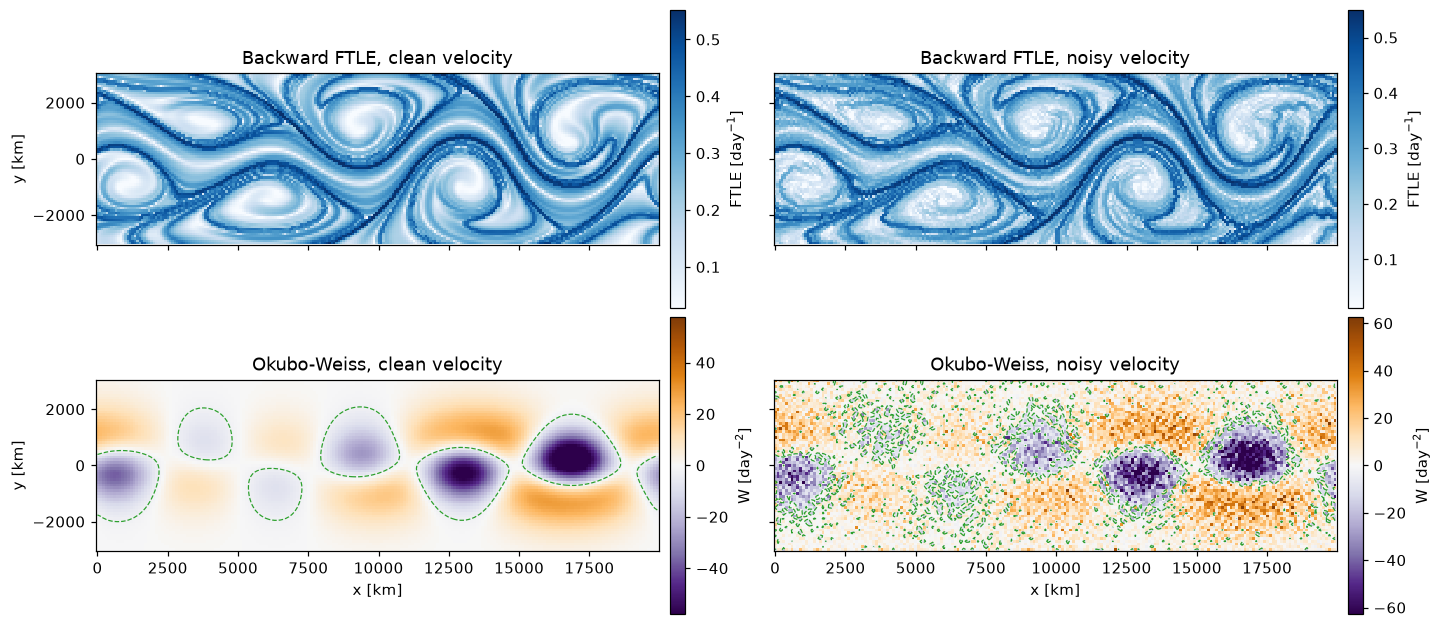

In [7]:
# Gridded "data": 100 km, 6-hourly, days 10 to 20. Five periods in x and a wide y range, because the
# interpolator is not periodic and particles must stay on the grid for the 10 days of backward integration.
x_grid = np.linspace(-2 * Lx, 3 * Lx, 1001)
y_grid = np.linspace(-6000, 6000, 121)
t_grid = np.arange(10, 20.01, 0.25)
T_E6 = 10.0
ds_clean = lk.sample_to_dataset(velocity, x_grid, y_grid, t_grid)
rms_speed = float(np.sqrt((ds_clean.u ** 2 + ds_clean.v ** 2).mean()))
ds_noisy = ds_clean.copy(deep=True)
ds_noisy["u"] = ds_clean.u + rng.normal(0, 0.05 * rms_speed, ds_clean.u.shape)
ds_noisy["v"] = ds_clean.v + rng.normal(0, 0.05 * rms_speed, ds_clean.v.shape)
print(f"rms speed {rms_speed:.0f} km/day, noise standard deviation {0.05 * rms_speed:.0f} km/day per component")

x = np.linspace(0, Lx, 240, endpoint=False)
y = np.linspace(-3000, 3000, 73)
X, Y = np.meshgrid(x, y)
res = {}
for name, ds in (("clean", ds_clean), ("noisy", ds_noisy)):
    vel_g = lk.grid_interpolator(ds, "u", "v")
    xf, yf, tau = lk.advect(X, Y, T0, -T_E6, DT, vel_g, return_exit=True)
    ftle, _ = lk.ftle_from_flowmap(xf, yf, x[1] - x[0], y[1] - y[0], T_E6, periodic_x=Lx, tau=tau)
    snap = ds.sel(time=T0).sel(x=slice(0, Lx - 1), y=slice(-3000, 3000))
    Wg = lk.okubo_weiss(snap.u.values, snap.v.values, x_grid[1] - x_grid[0], y_grid[1] - y_grid[0])[0]
    n_regions = ndimage.label(Wg < -0.2 * Wg.std())[1]
    res[name] = (ftle, Wg, snap.x.values, snap.y.values)
    print(f"{name}: particles that left the grid {int((tau < T_E6).sum())}, mean backward FTLE {np.nanmean(ftle):.3f} 1/day,"
          f" sigma_W {Wg.std():.1f}, Okubo-Weiss regions below threshold: {n_regions}")

ok = np.isfinite(res["clean"][0]) & np.isfinite(res["noisy"][0])
print(f"pattern correlation clean/noisy:  FTLE {np.corrcoef(res['clean'][0][ok], res['noisy'][0][ok])[0, 1]:.2f},"
      f"  W {np.corrcoef(res['clean'][1].ravel(), res['noisy'][1].ravel())[0, 1]:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 5.6), sharex=True, sharey=True, constrained_layout=True)
for j, name in enumerate(("clean", "noisy")):
    ftle, Wg, xs_, ys_ = res[name]
    lk.plot_field(axes[0, j], x, y, ftle, kind="ftle_bwd", label="FTLE [day$^{-1}$]", title=f"Backward FTLE, {name} velocity")
    lk.plot_field(axes[1, j], xs_, ys_, Wg, kind="okubo_weiss", label="W [day$^{-2}$]", title=f"Okubo-Weiss, {name} velocity")
    axes[1, j].contour(xs_, ys_, Wg, levels=[-0.2 * Wg.std()], colors="tab:green", linewidths=0.8)
    axes[1, j].set_xlabel("x [km]")
    axes[0, j].set_aspect("equal"); axes[1, j].set_aspect("equal")
axes[0, 0].set_ylabel("y [km]"); axes[1, 0].set_ylabel("y [km]")
plt.show()

**Answer.** With noise of 5% of the rms speed on every grid value:

- **Backward FTLE.** The map keeps its structure: the same ridges at the same places, pattern correlation 0.90 with the clean map, and the same mean (0.28 day⁻¹ for $T=10$ d). The noise shows up as graininess in the low-FTLE regions (eddy cores).
- **Okubo–Weiss.** The large-scale pattern survives (correlation 0.83) but the field is speckled, $\sigma_W$ rises from 14.4 to 17.4 day⁻², and the thresholded regions break up: 7 connected regions become about 700. As an eddy *detector* it no longer works without smoothing.

Why the difference: $W$ is a product of velocity **derivatives** at one instant. Differentiating white noise on a 100 km grid amplifies it, and squaring makes it worse. The FTLE is built from **trajectories**: a particle integrates the velocity over 10 days and over many grid cells, which averages uncorrelated noise out. Lagrangian diagnostics are, in this sense, a low-pass filter on the velocity errors.

Two cautions for the HF-radar practical. Real radar errors are not white: they are correlated in space and time (geometric dilution of precision near the baseline, gap filling, tides not resolved), and correlated errors do not average out along a trajectory. And the LAVD needs the vorticity, a derivative again, although it is then integrated along the trajectory.